# 15 · Models for nonideal flow

Given an RTD, what conversion will the reactor achieve? For a first-order reaction the RTD alone answers;
for any other order it depends also on *how* fluid elements mix, and two limiting models bracket the answer.
This notebook fits the tanks-in-series and axial-dispersion models to the tracer data, predicts conversion
with the segregation and maximum-mixedness models, and shows when the difference matters.

**What you will learn**
- fit the tanks-in-series and dispersion models to tracer data
- convert between n and Pe
- predict first-order conversion from an RTD
- bracket higher-order conversion with segregation and maximum mixedness

**Before you start:** notebook 14  ·  **Time:** about 60-75 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import datasets, rtd
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Tanks in series

tanks-in-series: n = 3.84 from the moments, n = 3.71 and tau = 39.7 s from the least-squares fit (the file was generated with n = 3.7)


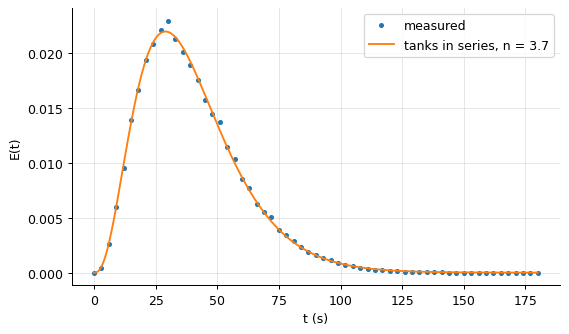

In [2]:
d = pd.read_csv(datasets.path("rtd_tracer_pulse.csv"), comment="#")
t, C = d.t_s.to_numpy(), d.C_g_m3.to_numpy()
base = np.polyfit(t[t > 140], C[t > 140], 1)
E = rtd.E_from_pulse(t, np.maximum(C - np.polyval(base, t), 0.0))
fit = rtd.fit_tanks_in_series(t, E)
print(f"tanks-in-series: n = {fit['n_moments']:.2f} from the moments, n = {fit['n']:.2f} and tau = {fit['tau']:.1f} s from the least-squares fit (the file was generated with n = 3.7)")
tt = np.linspace(0, 180, 400)
plt.plot(t, E, "o", ms=3, label="measured"); plt.plot(tt, rtd.tanks_in_series_E(tt, fit["tau"], fit["n"]), label=f"tanks in series, n = {fit['n']:.1f}"); plt.xlabel("t (s)"); plt.ylabel("E(t)"); plt.legend(); plt.show()

The tanks-in-series model has one parameter: $n$ tanks, with $\sigma^2/\tau^2 = 1/n$. The moments give $n$
directly; a least-squares fit refines it, and a non-integer $n$ is fine for the fit (the gamma function
interpolates). $n$ = 1 is a CSTR, $n \to \infty$ a PFR; this vessel is "about four tanks' worth" of mixing.

## The axial-dispersion model

sigma^2/tau^2 = 0.260 -> Peclet number Pe = uL/D = 6.5 (closed vessel); tanks-in-series equivalent n ~ Pe/2 = 3.2


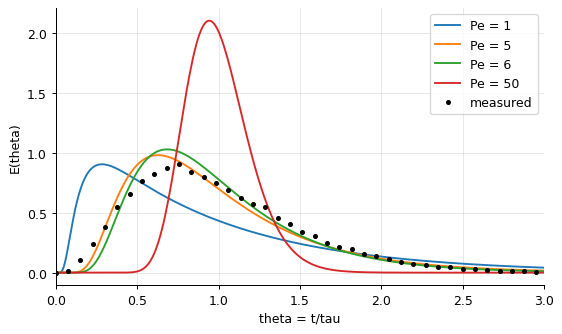

In [3]:
m = rtd.moments(t, E)
s2 = m["variance"] / m["mean"] ** 2
Pe = rtd.peclet_from_variance(s2, "closed")
print(f"sigma^2/tau^2 = {s2:.3f} -> Peclet number Pe = uL/D = {Pe:.1f} (closed vessel); tanks-in-series equivalent n ~ Pe/2 = {Pe/2:.1f}")
theta = np.linspace(0, 4, 400)
fig, ax = plt.subplots()
for Pe_ in (1.0, 5.0, Pe, 50.0):
    ax.plot(theta, rtd.dispersion_E(theta, Pe_), label=f"Pe = {Pe_:.0f}")
ax.plot(t / m["mean"], E * m["mean"], "ko", ms=3, label="measured")
ax.set(xlabel="theta = t/tau", ylabel="E(theta)", xlim=(0, 3)); ax.legend(); plt.show()

The dispersion model treats the reactor as plug flow with an axial diffusion-like spreading; its parameter is
the Peclet number, large for near-plug flow. Its E(θ) has the same skewed shape and the same variance
relation ($\sigma^2/\tau^2 = 2/Pe - 2/Pe^2(1 - e^{-Pe})$ for a closed vessel) - the two models fit tracer data
almost equally well, and for a first-order reaction predict almost the same conversion. Choose by
physics: tanks for stirred stages, dispersion for tubes and packed beds.

## Conversion from the RTD: first order

In [4]:
k = 0.05                                                            # 1/s
tau = m["mean"]
rows = [("PFR (ideal)", 1 - np.exp(-k * tau)), ("CSTR (ideal)", k * tau / (1 + k * tau)),
        (f"tanks in series, n = {fit['n']:.1f}", 1 - (1 + k * fit["tau"] / fit["n"]) ** (-fit["n"])),
        (f"dispersion, Pe = {Pe:.1f}", rtd.dispersion_conversion(k, tau, Pe)),
        ("segregation model on E(t)", rtd.segregation_conversion(t, E, k)), ("maximum mixedness on E(t)", rtd.maximum_mixedness_conversion(t, E, k))]
print(pd.DataFrame(rows, columns=["model", "conversion (first order)"]).round(4).to_string(index=False))

                    model  conversion (first order)
              PFR (ideal)                    0.8620
             CSTR (ideal)                    0.6645
 tanks in series, n = 3.7                    0.7962
     dispersion, Pe = 6.5                    0.8041
segregation model on E(t)                    0.7965
maximum mixedness on E(t)                    0.7961


For first order every model that reproduces the RTD gives the same conversion, because the reaction
rate is linear in concentration and the order of mixing does not matter: the RTD is a complete description.
The real vessel loses a few percent against the ideal PFR and gains a lot against a CSTR - the practical
meaning of "four tanks in series".

## Second order: mixing earliness matters

In [5]:
k2, C_A0 = 0.002, 25.0                                              # m3/(mol s), mol/m3: k2 C_A0 tau ~ 2
rows = []
for name, E_model in (("CSTR E(t)", rtd.cstr_E(t, tau)), ("measured E(t)", E), (f"{fit['n']:.1f} tanks", rtd.tanks_in_series_E(t, fit["tau"], fit["n"]))):
    seg = rtd.segregation_conversion(t, E_model, k2, 2, C_A0)
    mm = rtd.maximum_mixedness_conversion(t, E_model, k2, 2, C_A0)
    rows.append((name, seg, mm, seg - mm))
print(pd.DataFrame(rows, columns=["RTD", "segregation (late mixing)", "maximum mixedness (early)", "difference"]).round(4).to_string(index=False))
print(f"ideal CSTR, second order: {(1 + 2*k2*C_A0*tau - np.sqrt(1 + 4*k2*C_A0*tau))/(2*k2*C_A0*tau):.4f} (= maximum mixedness with the CSTR RTD)")

          RTD  segregation (late mixing)  maximum mixedness (early)  difference
    CSTR E(t)                     0.5314                     0.4975      0.0339
measured E(t)                     0.6260                     0.6005      0.0255
    3.7 tanks                     0.6259                     0.6002      0.0257
ideal CSTR, second order: 0.4984 (= maximum mixedness with the CSTR RTD)


For a second-order reaction, fluid that reacts as separate clumps (segregation, mixing at the last moment)
converts more than fluid mixed as early as possible, because the rate is convex in concentration. The two
models bracket the truth; the difference is largest for a CSTR-like RTD and shrinks as the vessel approaches
plug flow - for the measured RTD it is a percent. Whether a real reactor is nearer one limit is a question
of micromixing, decided by physics (viscosity, feed injection) rather than by the tracer curve.

## Inside the algorithm: the segregation model

In [6]:
Xb = 1 - np.exp(-k * t)
seg = (np.trapezoid(Xb * E, t) if hasattr(np, "trapezoid") else np.trapz(Xb * E, t)) / (np.trapezoid(E, t) if hasattr(np, "trapezoid") else np.trapz(E, t))
print("by hand: segregation conversion", round(seg, 4), "; library:", round(rtd.segregation_conversion(t, E, k), 4))

by hand: segregation conversion 0.7965 ; library: 0.7965


## Exercises
1. A 20 m packed bed with U = 0.5 m/s and D_ax = 0.02 m2/s: compute Pe, sigma^2/tau^2, the equivalent n, and the first-order conversion loss against plug flow for k tau = 3. At what Pe is the loss below 1 %?
2. For a half-order reaction (concave rate), which of segregation and maximum mixedness gives the higher conversion? Test with the CSTR RTD and explain with the shape of the rate law.
3. **Implement it yourself:** compute the conversion for n tanks in series analytically for first order, and by feeding the tanks-in-series E(t) into the segregation model; show they agree for n = 1, 2, 5.